### Naludaq Version
*Min Version*: `0.36.0`

## HDSoCv2_evalr2 ROI and WLC Mode

This notebook demostrates how to use ROI and WLC mode. Still experimental and parameters need to be explored.

### Compatible Boards
+ `HDSoCv1_evalr2`

## Imports

In [2]:
%load_ext autoreload
%autoreload 2
import time
import itertools
import numpy as np
from copy import deepcopy
from pathlib import Path


from naludaq.board import Board, startup_board
from naludaq.communication import AnalogRegisters, DigitalRegisters, ControlRegisters
from naludaq.parsers import get_parser
from naludaq.tools import get_pedestals_controller
from naludaq.tools.pedestals.pedestals_correcter import PedestalsCorrecter

from naludaq.backend import AcquisitionManager, ConnectionManager, RemoteAcquisition

import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# import logging


# def setup_logger(level=logging.DEBUG):
#     """Setup a basic logger."""
#     logger = logging.getLogger()
#     handler = logging.StreamHandler()
#     handler.setFormatter(
#         logging.Formatter("%(asctime)s %(name)-30s [%(levelname)-6s]: %(message)s")
#     )
#     logger.addHandler(handler)
#     logger.setLevel(level)
#     suppress = [
#         "naludaq.UART",
#         "naludaq.FTDI",
#     ]
#     # for name in suppress:
#     #     logging.getLogger(name).setLevel(logging.CRITICAL)
#     return logger


# try:
#     logger.debug("logger already setup")
# except:
#     logger = setup_logger()

## Function Definitions

In [3]:
def create_acquisition(name: str, board: Board, readout_metadata: dict = None) -> RemoteAcquisition:
    """Create an acquisition with the given name and optional readout metadata.
    Sets the output to the created acquisition and returns the acquisition object.
        Args:
            name (str): The name of the acquisition to be created.
            board (Board): The board object to be used for creating the acquisition.
            readout_metadata (dict, optional): A dictionary containing metadata for the readout. Defaults to None.
        Returns:
            RemoteAcquisition: The created acquisition object with the specified name and readout metadata.
    """
    am = AcquisitionManager(board)
    acquisition = am.create(name)
    acquisition.set_output()
    if readout_metadata:
        acquisition.readout_metadata = readout_metadata
    return acquisition

def parse_data(raw_data: dict, board: Board, correct_peds: bool = True) -> dict:
    """Parses an event dict that contains a 'rawdata' key.
        Args:
            raw_data (dict): A dictionary containing a 'rawdata' key with the raw data to be parsed.
            board (Board): The board object containing the parameters and pedestals for parsing.
            correct_peds (bool, optional): Whether to apply pedestal correction to the parsed event. Defaults to True.
        Returns:
            dict: A dictionary representing the parsed event.
    """
    PARSER = get_parser(board.params)
    evt = PARSER.parse(raw_data)
    if correct_peds:
        PC = PedestalsCorrecter(board.params, board.pedestals)
        PC.run(evt)
    return evt

def create_acq_name(base_name: str) -> str:
    """Create an acquisition name by appending a timestamp to the base name.
        Args:
            base_name (str): The base name to which the timestamp will be appended.
        Returns:
            str: The generated acquisition name with the timestamp in the form <base_name>_<timestamp>.
    """
    timestr = time.strftime("%Y-%m-%d-%H-%M-%S")
    return base_name + "_" + timestr

def clear_figs():
    """Clears all matplotlib figures"""
    plt.close("all")

def create_fig(figsize: tuple) -> plt.Figure:
    """Creates a matplotlib figure with the given size, constrained layout, and white background.
        Args:
            figsize (tuple): A tuple specifying the width and height of the figure.
        Returns:
            plt.Figure: A matplotlib figure object with the specified properties.
    """

    fig = plt.figure(figsize=figsize, constrained_layout=True)
    fig.set_facecolor('white')
    return fig

def plot_single_event(event, show: bool = True):
    """Plots a single event to the current matplotlib figure. Each channel is plotted separately with markers and a legend.
        Args:
            event (dict): A dictionary representing the event to be plotted.
            show (bool, optional): Whether to display the plot. Defaults to True.
    """
    for chan, chan_data in enumerate(event["data"]):
        if isinstance(chan_data, np.ndarray) and chan_data.size == 0:
            continue
        if len(chan_data) == 0:
            continue
        if np.all(np.isnan(chan_data)):
            continue
        plt.plot(chan_data, '.-', markersize=10, label=f"Channel {chan}")
    plt.legend(fontsize=12)
    if show:
        plt.show()


## Directory Setup

In [4]:
DATA_DIR = Path("./data").absolute()
DATA_DIR.mkdir(exist_ok=True)
SERVER_DIR = Path("./server").absolute()
SERVER_DIR.mkdir(exist_ok=True)
FIGURES_DIR = Path("figures").absolute()
FIGURES_DIR.mkdir(exist_ok=True)

## Board Initialization

In [5]:
BOARD = Board('hdsocv2_evalr2')
BOARD.start_server(str(SERVER_DIR))
BOARD_ADDRESS = ("192.168.1.60", 4660)
RECEIVER_ADDRESS = ("192.168.1.101", 4665)
SERVER_ADDRESS = (BOARD.context.address)
BOARD.connect_udp(BOARD_ADDRESS, RECEIVER_ADDRESS, SERVER_ADDRESS)
startup_board(BOARD)

/home/pixadmin/naluenv311/lib64/python3.11/site-packages/naluconfigs/__init__.py:312: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  data = np.loadtxt(filename, dtype=str, delimiter=",")


2026-11-20T22:36:09.708168Z  INFO ThreadId(13) src/web_api/mod.rs:41: Creating server
2026-11-20T22:36:09.708784Z  INFO ThreadId(13) src/web_api/mod.rs:94: Running server on 127.0.0.1:60769
2026-11-20T22:36:09.708807Z  INFO ThreadId(13) run: src/workers/mod.rs:82: Starting workers
2026-11-20T22:36:09.722695Z DEBUG ThreadId(02) run:run_packager_task_controller: src/workers/packager.rs:206: Starting packager: PackagerConfig { model: "hdsocv2_evalr2", event_stop_word: [202, 254], answer_stop_word: [202, 254] }
2026-11-20T22:36:09.722717Z DEBUG ThreadId(02) run_packager_impl: src/workers/packager.rs:256: Running package worker with config: PackagerConfig { model: "hdsocv2_evalr2", event_stop_word: [202, 254], answer_stop_word: [202, 254] }
2026-11-20T22:36:09.722722Z DEBUG ThreadId(02) run_packager_impl: src/workers/packager.rs:259: SELECTING HDSOC PACKAGER
2026-11-20T22:36:09.725694Z DEBUG ThreadId(12) run:run_packager_task_controller: src/workers/packager.rs:206: Starting packager: Packa

/home/pixadmin/naluenv311/lib64/python3.11/site-packages/naludaq/io/io_manager.py:452: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  data = np.loadtxt(filename, dtype=str, delimiter=",")


2026-11-20T22:36:10.303993Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 13, 01, 0B]
2026-11-20T22:36:10.304097Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 11, 00, 00]
2026-11-20T22:36:10.304204Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 10, 00, 00]
2026-11-20T22:36:10.304319Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 12, 00, 00]
2026-11-20T22:36:10.304424Z DEBUG ThreadId(19) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 0F, 42, EE]
2026-11-20T22:36:10.308426Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [CA, 00, 00, 00]
2026-11-20T22:36:10.321893Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381

True

In [18]:
startup_board(BOARD)

2026-11-20T23:00:49.662169Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 2D, 12, 39]
2026-11-20T23:00:49.662196Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 29, 01, 65]
2026-11-20T23:00:49.662201Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 2E, 12, 34]
2026-11-20T23:00:49.662205Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 2B, 01, 3C]
2026-11-20T23:00:49.662222Z DEBUG ThreadId(19) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 2C, C0, A8]
2026-11-20T23:00:49.662242Z DEBUG ThreadId(19) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 2A, C0, A8]
2026-11-20T23:00:49.662955Z DEBUG ThreadId(19) run:run_connection_task_controller: src/workers/connection.rs:381

True

## Signal Generator

### Signal Generator Settings

In [6]:
SINE_FREQ = 1 / (4 * 32 * 1e-9) # 4 windows, 128ns period
TRIGGER_FREQ = 1 / (1e-6) # 1 us period
PULSE_WIDTH = 50e-9
SINE_AMP = 0.3

# If using bursted pulses
N_CYCLES = 3
BURST_PERIOD = 1

### Signal Generator Setup

In [7]:
# CHANGED: generator controlled by hand from the front panel.
# ManualOutput is a no-op stand-in that keeps the rf_on()/rf_off() interface used later in the notebook.
class ManualOutput:
    """Stand-in for a generator output controlled by hand from the front panel."""

    def __init__(self, name: str):
        self.name = name

    def rf_on(self):
        pass  # switched by hand

    def rf_off(self):
        pass  # switched by hand

CHANNEL_INPUT = ManualOutput("sine -> signal channel")
TRIGGER_INPUT = ManualOutput("pulse burst -> external trigger")

print("Generator under manual control.")

Generator under manual control.


In [11]:
# CHANNEL_INPUT.rf_on()
# TRIGGER_INPUT.rf_on()


In [12]:
# TRIGGER_INPUT.manual_trigger()

In [8]:
CHANNEL_INPUT.rf_off()
TRIGGER_INPUT.rf_off()


## Data Capture Configuration

In [9]:
DAC_LEVEL = 1804 # (Default DAC Counts for HDSoCv1/2) Adjust depending on your board.

# You may have to adjust these parameters to center the pulse within the captured data.
WINDOWS = 2
LOOKBACK = 4
WAT = 0
READOUTCHANNELS = 60

ENABLED_READOUT_CHANNELS = [*range(BOARD.channels)]

READOUT_TIME = 2

# External Trigger, Trigger Relative Mode
READOUT_PARAMS = {
    "trig": "ext",
    "lb": "roi",
    "acq": "raw",
    "ped": "zero",
    "readoutEn": True,
    "singleEv": False,
}

READ_WINDOW = {
    "windows": WINDOWS,
    "lookback": LOOKBACK,
    "write_after_trig": WAT,
}

# Created to save with the acquisition metadata for reference when analyzing the data and plotting.
PARAMS = {
    "dac_level": DAC_LEVEL,
    "windows": WINDOWS,
    "lookback": LOOKBACK,
    "write_after_trig": WAT,
    "readoutchannels": READOUTCHANNELS,
    "n_cycle": N_CYCLES,
    "burst_period": BURST_PERIOD,
    "pulse_width": PULSE_WIDTH,
    "pulse_freq": TRIGGER_FREQ,
    "readout_time": READOUT_TIME,
    "readout_channels": ENABLED_READOUT_CHANNELS,
}

AR = AnalogRegisters(BOARD)
CR = ControlRegisters(BOARD)
DR = DigitalRegisters(BOARD)
AM = AcquisitionManager(BOARD)

### Set Board Configurations

In [10]:
CR.write("exttrig", 0)
BOARD.ext_bias.set_dacs(DAC_LEVEL)

2026-11-20T22:36:32.428725Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 04, 00, 40]
2026-11-20T22:36:32.429469Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [59, B0, 70, C0]
2026-11-20T22:36:32.429935Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [51, F0, 00, 00]
2026-11-20T22:36:32.430407Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [59, F0, 00, 00]
2026-11-20T22:36:32.430852Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [51, B0, 70, C0]
2026-11-20T22:36:32.431287Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [5A, B0, 70, C0]
2026-11-20T22:36:32.431717Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381

### Generate / Load Pedestals

In [19]:
PC = get_pedestals_controller(BOARD, num_captures=10, num_warmup_events=10)
PC.generate_pedestals()

2026-11-20T23:01:03.854674Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 13, 00, 05]
2026-11-20T23:01:03.854713Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 11, 00, 00]
2026-11-20T23:01:03.854734Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 10, 00, 00]
2026-11-20T23:01:03.854754Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 12, 00, 00]
2026-11-20T23:01:03.854758Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [AF, 0F, 41, 30]
2026-11-20T23:01:03.855449Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [CA, 00, 00, 00]
2026-11-20T23:01:03.856057Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381

### Setup Triggers
Set triggers accordingly to your threshold sweep.

In [20]:
SIGNAL_CHANNEL = 2       # channel the sine is connected to
TRIGGER_THRESHOLD = 37   # counts; noise-free and on the sine plateau (fine scan 2026-11-13, sine 0.3 Vpp, DAC 1804)

# External trigger decides WHEN an event is taken; in ROI mode this channel's discriminator
# decides WHICH windows are read out, so it must be armed on the signal channel.
trigger_values = [0] * BOARD.channels
trigger_values[SIGNAL_CHANNEL] = TRIGGER_THRESHOLD  # CHANGED: was channel 8, threshold 100
BOARD.trigger.values = trigger_values
BOARD.trigger.write_triggers()  # on v2 this also sets TSEL on every channel

# CHANGED (v2): four reference groups on v2 (v1 had two)
BOARD.trigger.references = {
    "0_15": (6, 10),
    "16_31": (6, 10),
    "32_47": (6, 10),
    "48_63": (6, 10),
}

# CHANGED (v2): v1's tsel_left/right and tsgn_left/right registers don't exist on v2.
# TSEL is set by write_triggers(); this sets TSGN = 1 on every channel, as in the v1 notebook.
BOARD.trigger.edges = True

2026-11-20T23:05:42.249692Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 01, B0, 0E]
2026-11-20T23:05:42.250846Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 01, C0, 0E]
2026-11-20T23:05:42.251595Z DEBUG ThreadId(16) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 01, D0, 0E]
2026-11-20T23:05:42.252289Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 01, E0, 0E]
2026-11-20T23:05:42.252984Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 01, F0, 0E]
2026-11-20T23:05:42.253709Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 02, 00, 0E]
2026-11-20T23:05:42.254405Z DEBUG ThreadId(12) run:run_connection_task_controller: src/workers/connection.rs:381

### Set Readout Settings

In [21]:
BOARD.readout.set_read_window(**READ_WINDOW)
BOARD.readout.set_readout_channels(ENABLED_READOUT_CHANNELS)

BOARD.readout.set_read_window(WINDOWS, LOOKBACK, WAT)
DR.write("readoutchannels", READOUTCHANNELS)

2026-11-20T23:05:51.636565Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 1C, 60, 02]
2026-11-20T23:05:51.637750Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 1C, 50, 04]
2026-11-20T23:05:51.638522Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 1C, 30, 00]
2026-11-20T23:05:51.639282Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 1A, 00, 00]
2026-11-20T23:05:51.639938Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 1A, 10, 00]
2026-11-20T23:05:51.640456Z DEBUG ThreadId(19) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 1A, 20, 00]
2026-11-20T23:05:51.640983Z DEBUG ThreadId(19) run:run_connection_task_controller: src/workers/connection.rs:381

### Enable WLC

In [22]:
DR.write("wlc_on", 1)

2026-11-20T23:05:53.242939Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B0, 1D, 50, 01]


### Create an Acquisition

In [23]:
ACQ_NAME = f"{BOARD.model}_WLC_ROI_windows{WINDOWS}"
acq_name = create_acq_name(ACQ_NAME)
readout_metadata = {"params": deepcopy(PARAMS)}
acq = create_acquisition(acq_name, BOARD, readout_metadata)
acq.pedestals = BOARD.pedestals

2026-11-20T23:05:55.408311Z DEBUG ThreadId(02) run:run_storager_task_controller: src/workers/storager.rs:180: Changing output acquisition to: "hdsocv2_evalr2_WLC_ROI_windows2_2026-11-20-13-05-55"
2026-11-20T23:05:55.408462Z DEBUG ThreadId(31) run_storager_impl: src/workers/storager.rs:231: Running storager for root: "hdsocv2_evalr2_WLC_ROI_windows2_2026-11-20-13-05-55"


### Readout Data

In [30]:
CHANNEL_INPUT.rf_on()
time.sleep(0.25)
try:
    BOARD.control.start_readout(**READOUT_PARAMS)
    TRIGGER_INPUT.rf_on()
    for _ in range(READOUT_TIME):
        time.sleep(1)
        print(len(acq))
finally:
    TRIGGER_INPUT.rf_off()
    CHANNEL_INPUT.rf_off()
    time.sleep(1)
    BOARD.control.stop_readout()
    time.sleep(0.25)

print(len(acq))

2026-11-20T23:07:20.472722Z DEBUG ThreadId(02) run:run_connection_task_controller: src/workers/connection.rs:381: Sending command: [B4, 30, 00, 18]
2026-11-20T23:07:20.526017Z DEBUG ThreadId(31) run_storager_impl: src/workers/storager.rs:311: Storager speed=0 KB/s, unwritten amount=0 KB
2026-11-20T23:07:20.546605Z DEBUG ThreadId(31) run_storager_impl: src/workers/storager.rs:258: No event received within timeout; flushing chunk
2026-11-20T23:07:21.413273Z DEBUG ThreadId(31) run_storager_impl: src/workers/storager.rs:258: No event received within timeout; flushing chunk
6
2026-11-20T23:07:22.394632Z DEBUG ThreadId(31) run_storager_impl: src/workers/storager.rs:311: Storager speed=0 KB/s, unwritten amount=0 KB
2026-11-20T23:07:22.415270Z DEBUG ThreadId(31) run_storager_impl: src/workers/storager.rs:258: No event received within timeout; flushing chunk
7
2026-11-20T23:07:23.395793Z DEBUG ThreadId(31) run_storager_impl: src/workers/storager.rs:311: Storager speed=0 KB/s, unwritten amount=0

Event 5: channels with data = [3]
Channel 3: 1984 samples, window labels [np.float64(16.0), np.float64(17.0), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(34.0), np.float64(35.0), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.f

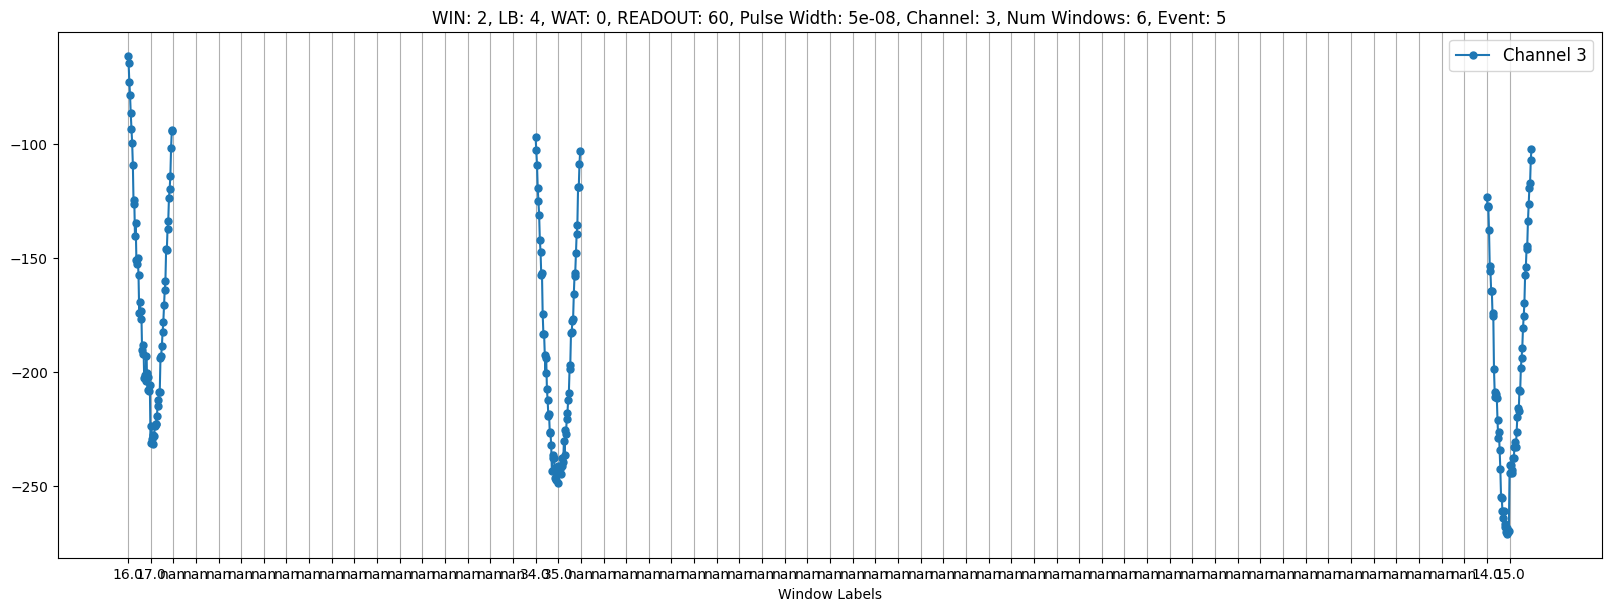

In [39]:
EVENT_IDX = 5


PARSER = get_parser(BOARD.params)
PC = PedestalsCorrecter(BOARD.params, BOARD.pedestals)
event = PC.run(acq.parsed_event(PARSER, EVENT_IDX))

# CHANGED: find which channels actually contain data instead of assuming channel 8
chans_with_data = [
    ch for ch, d in enumerate(event["data"])
    if len(d) > 0 and not np.all(np.isnan(d))
]
print(f"Event {EVENT_IDX}: channels with data = {chans_with_data}")
CHANNEL = SIGNAL_CHANNEL if SIGNAL_CHANNEL in chans_with_data else chans_with_data[0]

labels = event["window_labels"][CHANNEL]
num_windows = int(np.count_nonzero(~np.isnan(labels)))
print(f"Channel {CHANNEL}: {len(event['data'][CHANNEL])} samples, window labels {list(labels)}")

fig = create_fig(figsize=(16, 6))
plot_single_event(event, show=False)
plt.grid(True, axis="x")
ticks = [*range(0, len(event["data"][CHANNEL]), 32)]
plt.xticks(ticks, labels=labels[: len(ticks)])
plt.xlabel("Window Labels")
plt.title(f"WIN: {WINDOWS}, LB: {LOOKBACK}, WAT: {WAT}, READOUT: {READOUTCHANNELS}, "
          f"Pulse Width: {PULSE_WIDTH}, Channel: {CHANNEL}, Num Windows: {num_windows}, Event: {EVENT_IDX}")
plt.savefig(FIGURES_DIR / "wlc_roi.png")
plt.show()

In [29]:
event['window_labels'][3]

array([12., 13.])

In [33]:
# Which channels and windows each event contains
for i in range(len(acq)):
    ev = PC.run(acq.parsed_event(PARSER, i))
    chans = [ch for ch, d in enumerate(ev["data"]) if len(d) > 0 and not np.all(np.isnan(d))]
    wins = {ch: [int(w) for w in ev["window_labels"][ch] if not np.isnan(w)] for ch in chans}
    print(f"event {i}: channels {chans}, windows {wins}")

event 0: channels [3], windows {3: [12, 13]}
event 1: channels [3], windows {3: [4, 13, 36, 39, 7, 8]}
event 2: channels [3], windows {3: [42, 43, 2, 3, 46, 47]}
event 3: channels [3], windows {3: [52, 53, 22, 23, 56, 57]}
event 4: channels [3], windows {3: [60, 61]}
event 5: channels [3], windows {3: [16, 17, 34, 35, 14, 15]}
event 6: channels [3], windows {3: [41, 54, 45, 30, 51, 4]}
event 7: channels [3], windows {3: [38, 23, 43, 26, 31, 60]}


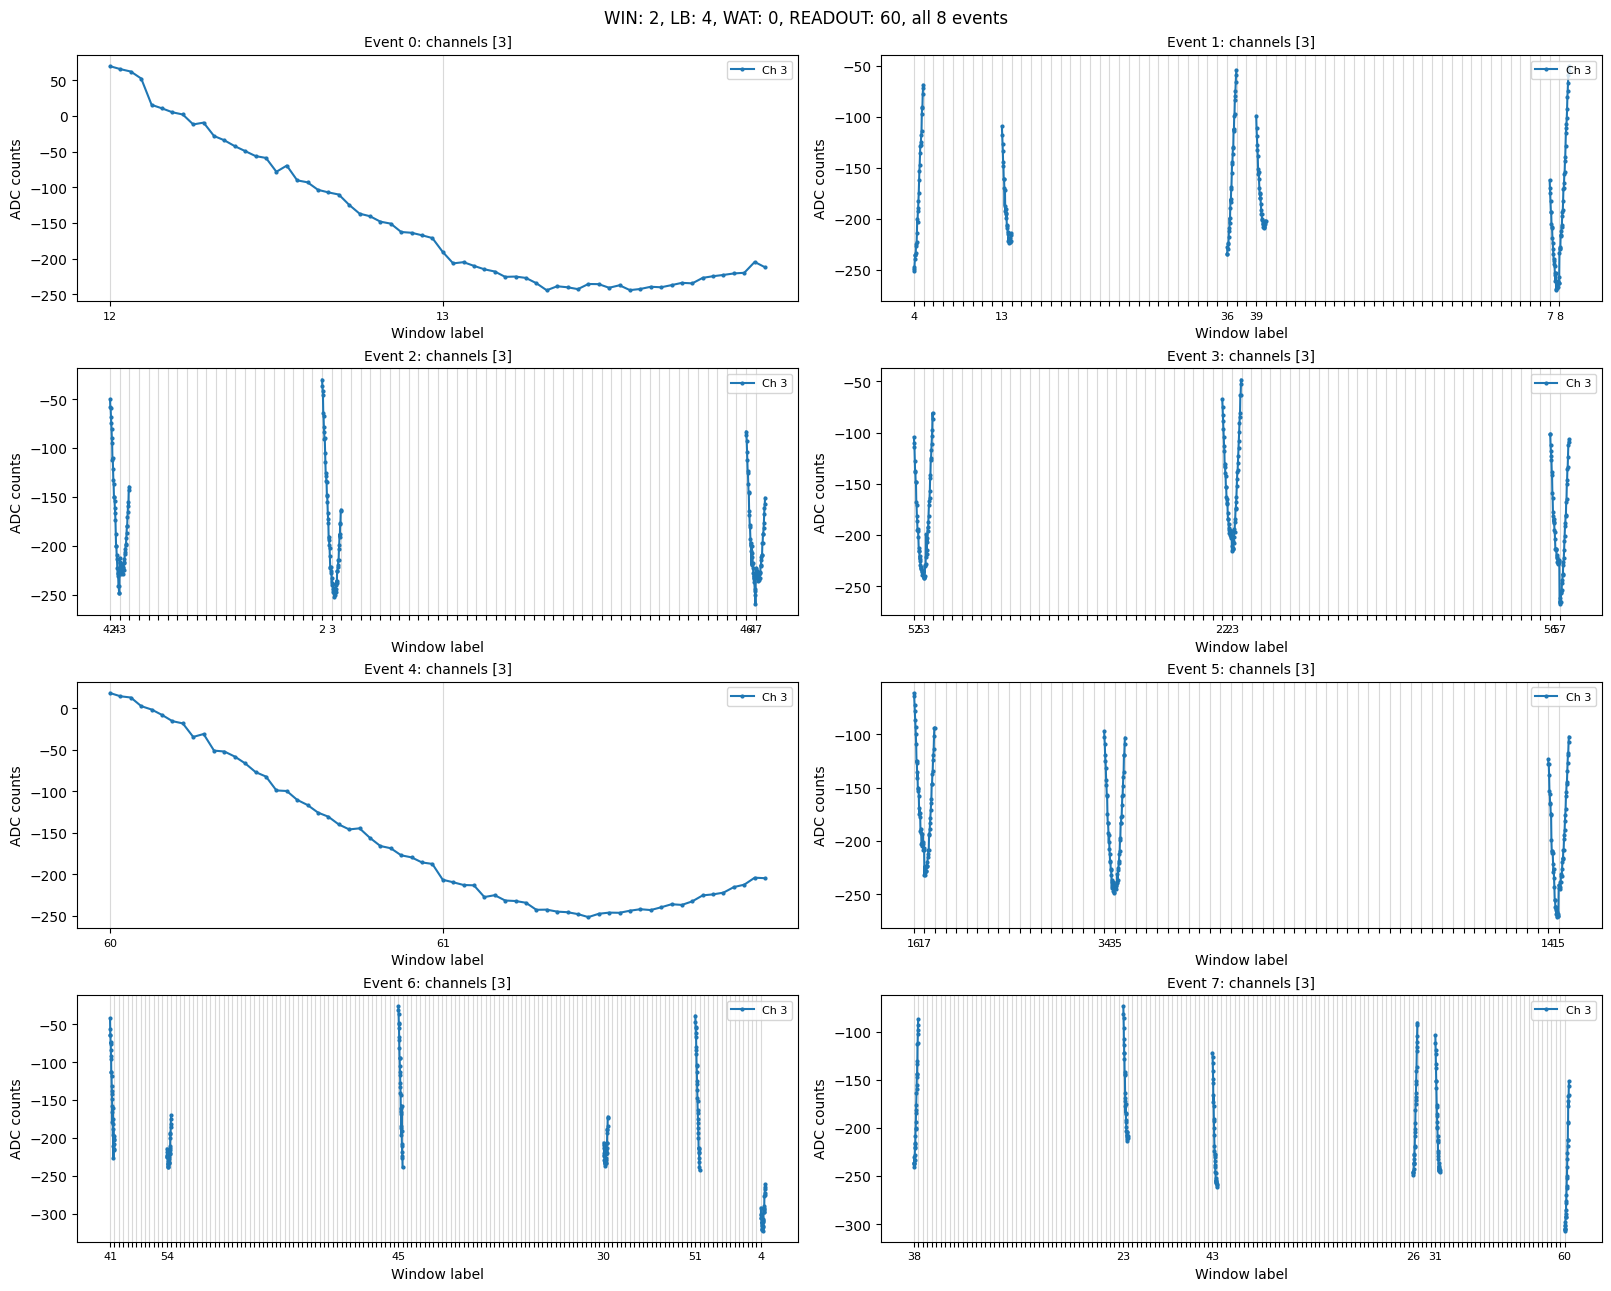

In [34]:
# Plot every event in the acquisition: one panel per event, all read-out windows, labelled by window number
SAMPLES_PER_WINDOW = 32
n_events = len(acq)
ncols = 2
nrows = int(np.ceil(n_events / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows), constrained_layout=True, squeeze=False)
fig.set_facecolor("white")

for i in range(n_events):
    ax = axes[i // ncols][i % ncols]
    ev = PC.run(acq.parsed_event(PARSER, i))
    chans = [ch for ch, d in enumerate(ev["data"]) if len(d) > 0 and not np.all(np.isnan(d))]
    for ch in chans:
        y = np.asarray(ev["data"][ch], dtype=float)
        ax.plot(y, ".-", markersize=4, label=f"Ch {ch}")
        labels = ev["window_labels"][ch]
        ticks = [*range(0, len(y), SAMPLES_PER_WINDOW)]
        ax.set_xticks(ticks)
        ax.set_xticklabels(["" if np.isnan(w) else int(w) for w in labels[: len(ticks)]], fontsize=8)
        for t in ticks:
            ax.axvline(t, color="0.85", lw=0.8, zorder=0)
    ax.set_title(f"Event {i}: channels {chans}", fontsize=10)
    ax.set_xlabel("Window label")
    ax.set_ylabel("ADC counts")
    ax.legend(fontsize=8, loc="upper right")

for j in range(n_events, nrows * ncols):
    axes[j // ncols][j % ncols].axis("off")

fig.suptitle(f"WIN: {WINDOWS}, LB: {LOOKBACK}, WAT: {WAT}, READOUT: {READOUTCHANNELS}, all {n_events} events")
plt.savefig(FIGURES_DIR / "wlc_roi_all_events.png")
plt.show()

In [40]:
# Save every event in the acquisition as its own figure:
#   figures/<acquisition name>/event_0000.png, event_0001.png, ...
SAMPLES_PER_WINDOW = 32
acq_label = getattr(acq, "name", acq_name)
event_dir = FIGURES_DIR / acq_label
event_dir.mkdir(parents=True, exist_ok=True)

for i in range(len(acq)):
    ev = PC.run(acq.parsed_event(PARSER, i))
    chans = [ch for ch, d in enumerate(ev["data"]) if len(d) > 0 and not np.all(np.isnan(d))]
    if not chans:
        print(f"event {i}: no channels with data, skipped")
        continue

    fig = create_fig(figsize=(12, 4))
    for ch in chans:
        y = np.asarray(ev["data"][ch], dtype=float)
        plt.plot(y, ".-", markersize=6, label=f"Channel {ch}")
    ch0 = chans[0]
    labels = ev["window_labels"][ch0]
    ticks = [*range(0, len(ev["data"][ch0]), SAMPLES_PER_WINDOW)]
    plt.xticks(ticks, labels=["" if np.isnan(w) else int(w) for w in labels[: len(ticks)]])
    plt.grid(True, axis="x")
    num_windows = int(np.count_nonzero(~np.isnan(labels)))
    plt.xlabel("Window label")
    plt.ylabel("ADC counts")
    plt.title(f"{acq_label} | WIN: {WINDOWS}, LB: {LOOKBACK}, WAT: {WAT}, READOUT: {READOUTCHANNELS}, "
              f"Channels: {chans}, Num Windows: {num_windows}, Event: {i}")
    plt.legend()
    plt.savefig(event_dir / f"event_{i:04d}.png")
    plt.close(fig)  # don't display or keep every figure open

print(f"Saved {len(acq)} event figures to {event_dir}")

Saved 8 event figures to /home/pixadmin/HDSOCv1_evalr2_ROI/figures/hdsocv2_evalr2_WLC_ROI_windows2_2026-11-20-13-05-55
